# 02. Exploratory Data Analysis (EDA)

Pertanyaan yang ingin dijawab:
1. Seperti apa tren dan dampak COVID pada seri?
2. Seberapa kuat pola musiman, dan bulan apa yang rutin naik atau turun?
3. Seberapa besar efek Lebaran dan jumlah hari kerja?
4. Apakah seri stasioner? Berapa differencing yang diperlukan? (untuk SARIMAX)
5. Apakah penumpang pasca-COVID benar-benar mendatar? (hipotesis kapasitas)

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

FOLDER_GAMBAR = "../reports/figures"
os.makedirs(FOLDER_GAMBAR, exist_ok=True)

# awal periode pasca-COVID (dipakai di beberapa analisis)
PASCA_COVID = "2023-01-01"
COVID_MULAI = "2020-03-01"
COVID_AKHIR = "2022-12-31"

def simpan_gambar(nama_file):
    plt.savefig(os.path.join(FOLDER_GAMBAR, nama_file), dpi=150, bbox_inches="tight")

In [2]:
df = pd.read_csv("../data/processed/data_final.csv", parse_dates=["tanggal"])
df = df.set_index("tanggal").asfreq("MS")     # pastikan frekuensi bulanan (Month Start)

df["penumpang_juta"] = df["penumpang_ribu"] / 1000    # lebih mudah dibaca
df["tahun"] = df.index.year
df["bulan"] = df.index.month

print("Ukuran data :", df.shape)
print("Rentang     :", df.index.min().date(), "sampai", df.index.max().date())
print("Nilai kosong:", df["penumpang_ribu"].isna().sum())
print()
print(df.head())

Ukuran data : (128, 10)
Rentang     : 2016-01-01 sampai 2026-08-01
Nilai kosong: 0

           year_month  penumpang_ribu  total_hari  jumlah_hari_kerja  \
tanggal                                                                
2016-01-01    2016-01         22238.0          31                 20   
2016-02-01    2016-02         21229.0          29                 20   
2016-03-01    2016-03         23206.0          31                 21   
2016-04-01    2016-04         23149.0          30                 21   
2016-05-01    2016-05         24401.0          31                 20   

            jumlah_libur_nasional_weekday  is_lebaran  is_covid  \
tanggal                                                           
2016-01-01                              1           0         0   
2016-02-01                              1           0         0   
2016-03-01                              2           0         0   
2016-04-01                              0           0         0   
2016-05-0

In [3]:
print("=== Seluruh data ===")
print(df["penumpang_juta"].describe().round(2))

df_normal = df[df["is_covid"] == 0]     # data di luar COVID
print("\n=== Di luar periode COVID ===")
print(df_normal["penumpang_juta"].describe().round(2))

print("\n=== Periode COVID ===")
print(df[df["is_covid"] == 1]["penumpang_juta"].describe().round(2))

=== Seluruh data ===
count    128.00
mean      23.26
std        6.98
min        5.08
25%       21.12
50%       25.58
75%       28.26
max       32.47
Name: penumpang_juta, dtype: float64

=== Di luar periode COVID ===
count    94.00
mean     26.92
std       2.61
min      20.81
25%      25.00
50%      27.52
75%      28.85
max      32.47
Name: penumpang_juta, dtype: float64

=== Periode COVID ===
count    34.00
mean     13.15
std       5.00
min       5.08
25%      10.13
50%      12.01
75%      16.78
max      23.12
Name: penumpang_juta, dtype: float64


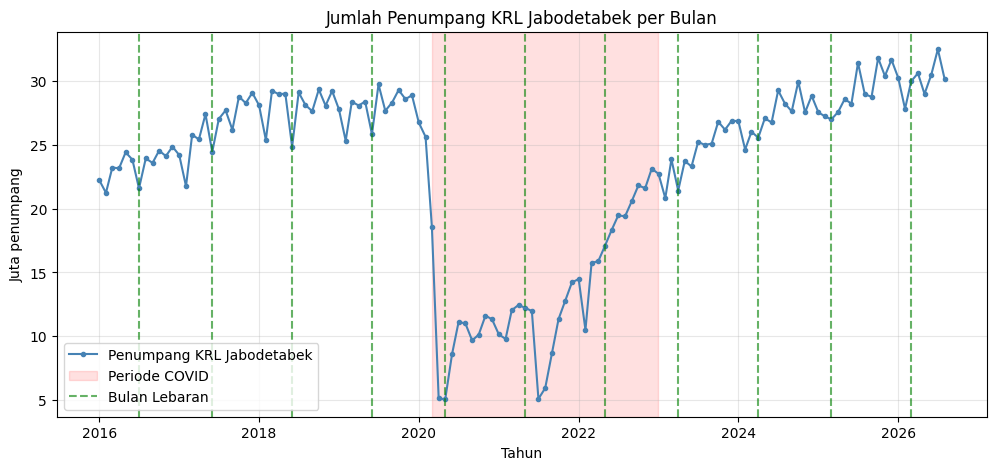

In [4]:
fig, ax = plt.subplots()
ax.plot(df.index, df["penumpang_juta"], marker="o", markersize=3, color="steelblue",
        label="Penumpang KRL Jabodetabek")

# blok merah = periode COVID
ax.axvspan(pd.Timestamp(COVID_MULAI), pd.Timestamp(COVID_AKHIR),
           color="red", alpha=0.12, label="Periode COVID")

# garis hijau putus-putus = bulan Lebaran
tanggal_lebaran = df.index[df["is_lebaran"] == 1]
for i, tgl in enumerate(tanggal_lebaran):
    ax.axvline(tgl, color="green", linestyle="--", alpha=0.6,
               label="Bulan Lebaran" if i == 0 else None)

ax.set_title("Jumlah Penumpang KRL Jabodetabek per Bulan")
ax.set_xlabel("Tahun")
ax.set_ylabel("Juta penumpang")
ax.legend()
simpan_gambar("eda_01_seri_waktu.png")
plt.show()

       jumlah_bulan  total_juta  rata_bulanan_juta  pertumbuhan_rata_%
tahun                                                                 
2016             12      280.59              23.38                 NaN
2017             12      315.85              26.32               12.57
2018             12      336.80              28.07                6.63
2019             12      336.04              28.00               -0.22
2020             12      154.59              12.88              -54.00
2021             12      126.74              10.56              -18.02
2022             12      217.96              18.16               71.98
2023             12      290.89              24.24               33.46
2024             12      328.15              27.35               12.81
2025             12      348.90              29.07                6.32
2026              8      240.60              30.08                3.44

Catatan: tahun dengan jumlah_bulan < 12 belum lengkap, total_juta-nya tidak 

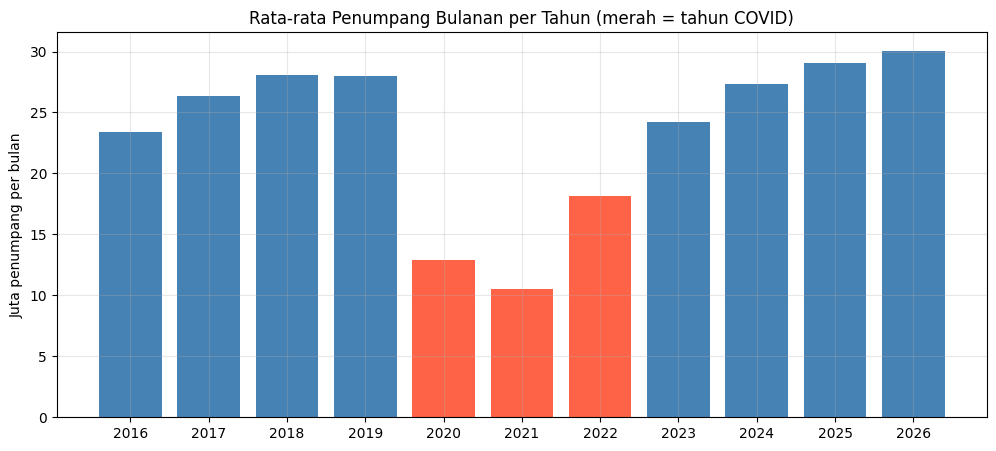

In [5]:
tahunan = df.groupby("tahun").agg(
    jumlah_bulan=("penumpang_juta", "count"),
    total_juta=("penumpang_juta", "sum"),
    rata_bulanan_juta=("penumpang_juta", "mean"),
)

# pertumbuhan dihitung dari RATA-RATA bulanan (bukan total),
# supaya tahun yang belum lengkap tetap bisa dibandingkan
tahunan["pertumbuhan_rata_%"] = tahunan["rata_bulanan_juta"].pct_change() * 100
print(tahunan.round(2))
print("\nCatatan: tahun dengan jumlah_bulan < 12 belum lengkap, total_juta-nya tidak sebanding.")
print("Rata-rata bulanan tahun tidak lengkap bisa bias karena pengaruh musiman.")

# grafik rata-rata bulanan per tahun
fig, ax = plt.subplots()
warna = ["tomato" if th in [2020, 2021, 2022] else "steelblue" for th in tahunan.index]
ax.bar(tahunan.index.astype(str), tahunan["rata_bulanan_juta"], color=warna)
ax.set_title("Rata-rata Penumpang Bulanan per Tahun (merah = tahun COVID)")
ax.set_ylabel("Juta penumpang per bulan")
simpan_gambar("eda_02_rata_tahunan.png")
plt.show()

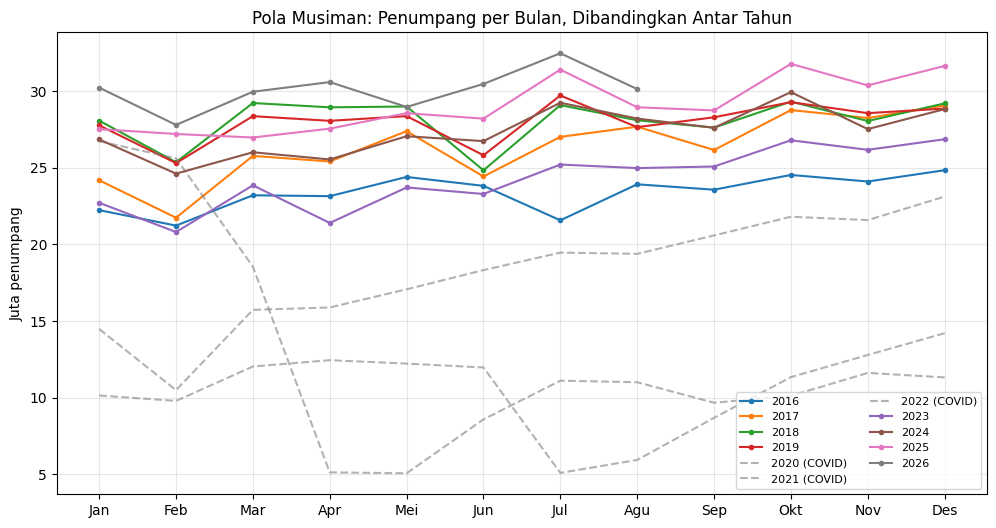

In [6]:
tabel_musim = df.pivot_table(index="bulan", columns="tahun", values="penumpang_juta")

fig, ax = plt.subplots(figsize=(12, 6))
for th in tabel_musim.columns:
    if th in [2020, 2021, 2022]:
        ax.plot(tabel_musim.index, tabel_musim[th], linestyle="--", color="gray",
                alpha=0.6, label=f"{th} (COVID)")
    else:
        ax.plot(tabel_musim.index, tabel_musim[th], marker="o", markersize=3, label=str(th))

ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "Mei", "Jun",
                    "Jul", "Agu", "Sep", "Okt", "Nov", "Des"])
ax.set_title("Pola Musiman: Penumpang per Bulan, Dibandingkan Antar Tahun")
ax.set_ylabel("Juta penumpang")
ax.legend(ncol=2, fontsize=8)
simpan_gambar("eda_03_pola_musiman.png")
plt.show()

Tahun yang dipakai untuk indeks musiman: [2016, 2017, 2018, 2019, 2023, 2024, 2025]


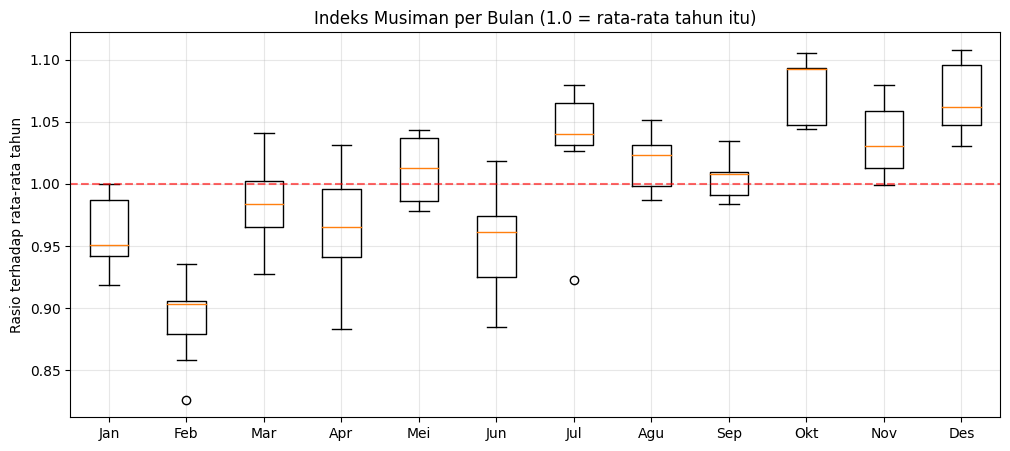

        mean    min    max  count
bulan                            
1      0.961  0.919  1.000      7
2      0.891  0.826  0.936      7
3      0.984  0.928  1.041      7
4      0.965  0.883  1.031      7
5      1.011  0.978  1.044      7
6      0.952  0.885  1.019      7
7      1.034  0.923  1.080      7
8      1.017  0.987  1.052      7
9      1.004  0.984  1.035      7
10     1.075  1.045  1.105      7
11     1.036  0.999  1.080      7
12     1.070  1.031  1.108      7


In [7]:
# Idea: bagi nilai tiap bulan dengan rata-rata tahunnya.
# Hasilnya >1 berarti bulan itu di atas rata-rata tahun, <1 berarti di bawah.
# Hanya dipakai pada tahun yang lengkap 12 bulan dan bebas COVID.

tahun_dipakai = []
for th in df["tahun"].unique():
    bagian = df[df["tahun"] == th]
    if len(bagian) == 12 and bagian["is_covid"].sum() == 0:
        tahun_dipakai.append(th)
print("Tahun yang dipakai untuk indeks musiman:", tahun_dipakai)

df["rasio_musiman"] = np.nan
for th in tahun_dipakai:
    mask = df["tahun"] == th
    rata_tahun = df.loc[mask, "penumpang_juta"].mean()
    df.loc[mask, "rasio_musiman"] = df.loc[mask, "penumpang_juta"] / rata_tahun

# boxplot per bulan
data_box = []
for b in range(1, 13):
    nilai_bulan = df.loc[df["bulan"] == b, "rasio_musiman"].dropna()
    data_box.append(nilai_bulan.values)

fig, ax = plt.subplots(figsize=(12, 5))
ax.boxplot(data_box, labels=["Jan", "Feb", "Mar", "Apr", "Mei", "Jun",
                             "Jul", "Agu", "Sep", "Okt", "Nov", "Des"])
ax.axhline(1, color="red", linestyle="--", alpha=0.6)
ax.set_title("Indeks Musiman per Bulan (1.0 = rata-rata tahun itu)")
ax.set_ylabel("Rasio terhadap rata-rata tahun")
simpan_gambar("eda_04_indeks_musiman.png")
plt.show()

# tabel rata-rata indeks
ringkas_musim = df.groupby("bulan")["rasio_musiman"].agg(["mean", "min", "max", "count"]).round(3)
print(ringkas_musim)

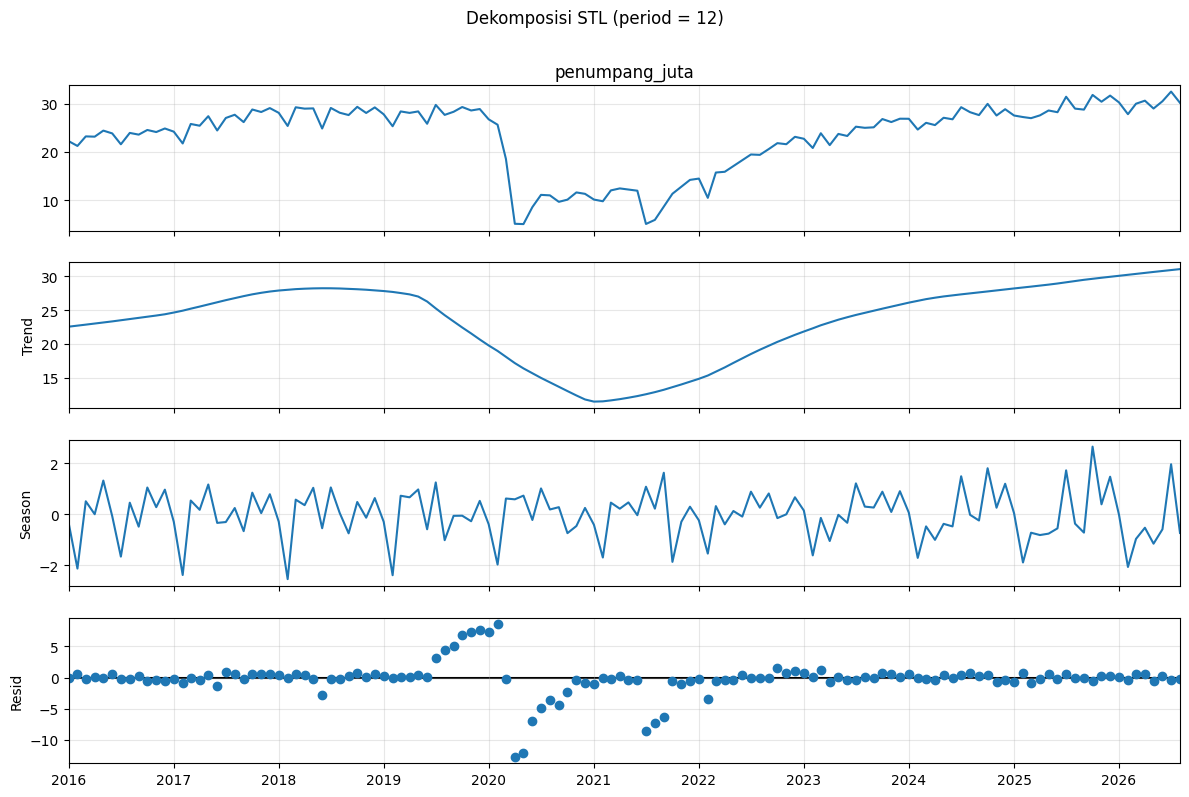

Kekuatan tren    : 0.844
Kekuatan musiman : 0.017

8 bulan dengan residual terbesar:
tanggal
2020-04-01    12.67
2020-05-01    12.10
2021-07-01     8.62
2020-02-01     8.58
2019-12-01     7.63
2020-01-01     7.30
2019-11-01     7.25
2021-08-01     7.22
Name: resid, dtype: float64


In [8]:
seri = df["penumpang_juta"]

# STL memisahkan: tren + musiman + sisa (residual)
# robust=True supaya outlier COVID tidak terlalu merusak komponen musiman
stl = STL(seri, period=12, robust=True).fit()

fig = stl.plot()
fig.set_size_inches(12, 8)
fig.suptitle("Dekomposisi STL (period = 12)", y=1.02)
simpan_gambar("eda_05_stl.png")
plt.show()

# kekuatan tren dan musiman (0 = lemah, 1 = kuat)
var_sisa = np.var(stl.resid)
kekuatan_tren = max(0, 1 - var_sisa / np.var(stl.trend + stl.resid))
kekuatan_musiman = max(0, 1 - var_sisa / np.var(stl.seasonal + stl.resid))
print(f"Kekuatan tren    : {kekuatan_tren:.3f}")
print(f"Kekuatan musiman : {kekuatan_musiman:.3f}")

# residual terbesar = bulan paling "tidak biasa"
sisa_abs = stl.resid.abs().sort_values(ascending=False).head(8)
print("\n8 bulan dengan residual terbesar:")
print(sisa_abs.round(2))

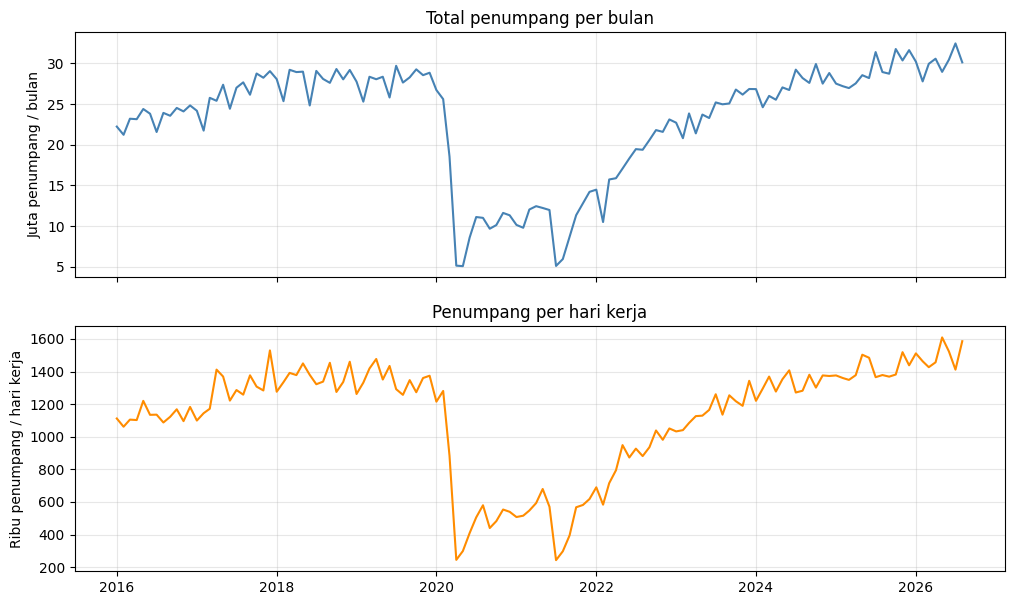

In [9]:
# penumpang per hari kerja = menghilangkan pengaruh jumlah hari kerja
df["penumpang_per_hari_kerja_ribu"] = df["penumpang_ribu"] / df["jumlah_hari_kerja"]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax1.plot(df.index, df["penumpang_juta"], color="steelblue")
ax1.set_ylabel("Juta penumpang / bulan")
ax1.set_title("Total penumpang per bulan")

ax2.plot(df.index, df["penumpang_per_hari_kerja_ribu"], color="darkorange")
ax2.set_ylabel("Ribu penumpang / hari kerja")
ax2.set_title("Penumpang per hari kerja")
simpan_gambar("eda_06_per_hari_kerja.png")
plt.show()

Korelasi (data tahun lengkap non-COVID):
                               rasio_musiman  jumlah_hari_kerja  \
rasio_musiman                          1.000              0.570   
jumlah_hari_kerja                      0.570              1.000   
jumlah_libur_nasional_weekday         -0.311             -0.637   
is_lebaran                            -0.428             -0.356   

                               jumlah_libur_nasional_weekday  is_lebaran  
rasio_musiman                                         -0.311      -0.428  
jumlah_hari_kerja                                     -0.637      -0.356  
jumlah_libur_nasional_weekday                          1.000       0.264  
is_lebaran                                             0.264       1.000  


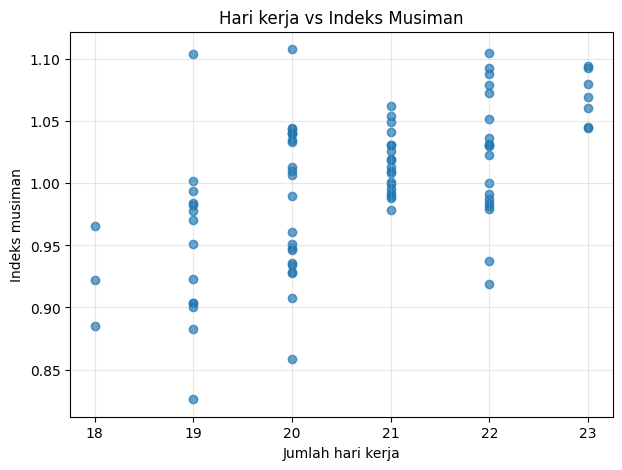

In [10]:
# korelasi memakai indeks musiman, supaya tren tidak mengacaukan hasil
df_rasio = df.dropna(subset=["rasio_musiman"])
kolom_korelasi = ["rasio_musiman", "jumlah_hari_kerja",
                  "jumlah_libur_nasional_weekday", "is_lebaran"]
print("Korelasi (data tahun lengkap non-COVID):")
print(df_rasio[kolom_korelasi].corr().round(3))

# scatter hari kerja vs indeks musiman
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df_rasio["jumlah_hari_kerja"], df_rasio["rasio_musiman"], alpha=0.7)
ax.set_xlabel("Jumlah hari kerja")
ax.set_ylabel("Indeks musiman")
ax.set_title("Hari kerja vs Indeks Musiman")
simpan_gambar("eda_07_hari_kerja_scatter.png")
plt.show()

In [11]:
# Bandingkan bulan Lebaran dengan rata-rata bulan sebelum dan sesudahnya.
# Hanya bulan Lebaran di luar COVID, dan tetangganya juga bukan COVID.

hasil_lebaran = []
for tgl in df.index[(df["is_lebaran"] == 1) & (df["is_covid"] == 0)]:
    sebelum = tgl - pd.DateOffset(months=1)
    sesudah = tgl + pd.DateOffset(months=1)

    if sebelum not in df.index or sesudah not in df.index:
        continue
    if df.loc[sebelum, "is_covid"] == 1 or df.loc[sesudah, "is_covid"] == 1:
        continue

    nilai = df.loc[tgl, "penumpang_juta"]
    rata_tetangga = (df.loc[sebelum, "penumpang_juta"] + df.loc[sesudah, "penumpang_juta"]) / 2
    selisih_persen = (nilai / rata_tetangga - 1) * 100

    hasil_lebaran.append({
        "bulan_lebaran": tgl.strftime("%Y-%m"),
        "nilai_juta": round(nilai, 2),
        "rata_tetangga_juta": round(rata_tetangga, 2),
        "selisih_%": round(selisih_persen, 1),
    })

tabel_lebaran = pd.DataFrame(hasil_lebaran)
print(tabel_lebaran)
print(f"\nRata-rata efek Lebaran: {tabel_lebaran['selisih_%'].mean():.1f}%")

# cek apakah bulan sebelum dan sesudah Lebaran juga terpengaruh
# (menentukan perlunya fitur lebaran_lag1 dan lebaran_lead1)
print("\nIndeks musiman di sekitar Lebaran (non-COVID):")
for tgl in df.index[(df["is_lebaran"] == 1) & (df["is_covid"] == 0)]:
    if pd.isna(df.loc[tgl, "rasio_musiman"]):
        continue
    sebelum = tgl - pd.DateOffset(months=1)
    sesudah = tgl + pd.DateOffset(months=1)
    r_sebelum = df["rasio_musiman"].get(sebelum, np.nan)
    r_lebaran = df.loc[tgl, "rasio_musiman"]
    r_sesudah = df["rasio_musiman"].get(sesudah, np.nan)
    print(f"{tgl.strftime('%Y-%m')}: sebelum={r_sebelum:.3f} | Lebaran={r_lebaran:.3f} | sesudah={r_sesudah:.3f}")

  bulan_lebaran  nilai_juta  rata_tetangga_juta  selisih_%
0       2016-07       21.57               23.87       -9.6
1       2017-06       24.43               27.20      -10.2
2       2018-06       24.83               29.04      -14.5
3       2019-06       25.82               29.04      -11.1
4       2023-04       21.40               23.79      -10.0
5       2024-04       25.54               26.53       -3.7
6       2025-03       26.97               27.38       -1.5
7       2026-03       29.96               29.19        2.6

Rata-rata efek Lebaran: -7.2%

Indeks musiman di sekitar Lebaran (non-COVID):
2016-07: sebelum=1.019 | Lebaran=0.923 | sesudah=1.023
2017-06: sebelum=1.040 | Lebaran=0.928 | sesudah=1.026
2018-06: sebelum=1.033 | Lebaran=0.885 | sesudah=1.036
2019-06: sebelum=1.013 | Lebaran=0.922 | sesudah=1.061
2023-04: sebelum=0.984 | Lebaran=0.883 | sesudah=0.978
2024-04: sebelum=0.951 | Lebaran=0.934 | sesudah=0.989
2025-03: sebelum=0.936 | Lebaran=0.928 | sesudah=0.948


In [12]:
def uji_stasioner(seri, nama):
    """
    ADF : H0 = seri TIDAK stasioner. p < 0.05 -> stasioner.
    KPSS: H0 = seri stasioner.       p > 0.05 -> stasioner.
    """
    seri = seri.dropna()
    p_adf = adfuller(seri, autolag="AIC")[1]
    p_kpss = kpss(seri, regression="c", nlags="auto")[1]

    adf_ok = p_adf < 0.05
    kpss_ok = p_kpss > 0.05

    if adf_ok and kpss_ok:
        kesimpulan = "STASIONER"
    elif (not adf_ok) and (not kpss_ok):
        kesimpulan = "TIDAK stasioner"
    else:
        kesimpulan = "meragukan (kedua uji beda hasil)"

    print(f"{nama:28s} n={len(seri):3d} | ADF p={p_adf:.4f} | KPSS p={p_kpss:.4f} | {kesimpulan}")


subset = {
    "Seluruh data": df["penumpang_juta"],
    "Pasca-COVID (>=2023)": df.loc[df.index >= PASCA_COVID, "penumpang_juta"],
}

for nama_subset, seri_sub in subset.items():
    print(f"\n=== {nama_subset} ===")
    uji_stasioner(seri_sub, "Level (asli)")
    uji_stasioner(seri_sub.diff(), "Diff 1 (d=1)")
    uji_stasioner(seri_sub.diff(12), "Diff musiman 12 (D=1)")
    uji_stasioner(seri_sub.diff().diff(12), "Diff 1 + musiman 12")


=== Seluruh data ===
Level (asli)                 n=128 | ADF p=0.3967 | KPSS p=0.1000 | meragukan (kedua uji beda hasil)
Diff 1 (d=1)                 n=127 | ADF p=0.0989 | KPSS p=0.1000 | meragukan (kedua uji beda hasil)
Diff musiman 12 (D=1)        n=116 | ADF p=0.1519 | KPSS p=0.1000 | meragukan (kedua uji beda hasil)
Diff 1 + musiman 12          n=115 | ADF p=0.0000 | KPSS p=0.1000 | STASIONER

=== Pasca-COVID (>=2023) ===
Level (asli)                 n= 44 | ADF p=0.4857 | KPSS p=0.0100 | TIDAK stasioner
Diff 1 (d=1)                 n= 43 | ADF p=0.0002 | KPSS p=0.1000 | STASIONER
Diff musiman 12 (D=1)        n= 32 | ADF p=0.0012 | KPSS p=0.0347 | meragukan (kedua uji beda hasil)
Diff 1 + musiman 12          n= 31 | ADF p=0.0000 | KPSS p=0.0778 | STASIONER


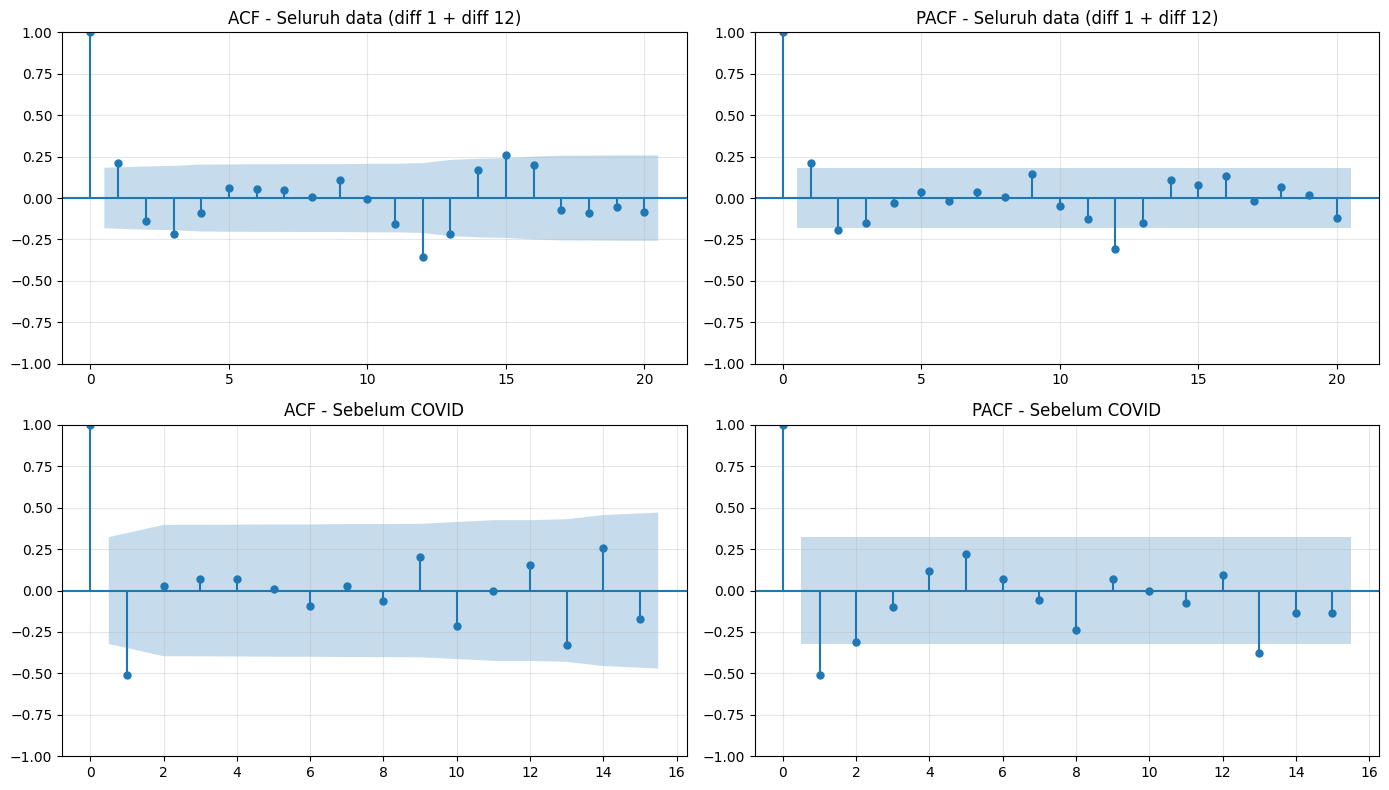

Jumlah titik versi seluruh data : 115
Jumlah titik versi pra-COVID    : 37


In [13]:
# Dipakai untuk menebak orde p, q (non-musiman) dan P, Q (musiman).
# Dua versi: seluruh data, dan sebelum COVID (karena COVID merusak pola ACF).

seri_penuh = df["penumpang_juta"].diff().diff(12).dropna()
seri_pra_covid = df.loc[df.index < COVID_MULAI, "penumpang_juta"].diff().diff(12).dropna()

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

plot_acf(seri_penuh, lags=20, ax=axes[0, 0])
axes[0, 0].set_title("ACF - Seluruh data (diff 1 + diff 12)")
plot_pacf(seri_penuh, lags=20, ax=axes[0, 1], method="ywm")
axes[0, 1].set_title("PACF - Seluruh data (diff 1 + diff 12)")

plot_acf(seri_pra_covid, lags=15, ax=axes[1, 0])
axes[1, 0].set_title("ACF - Sebelum COVID")
plot_pacf(seri_pra_covid, lags=15, ax=axes[1, 1], method="ywm")
axes[1, 1].set_title("PACF - Sebelum COVID")

plt.tight_layout()
simpan_gambar("eda_08_acf_pacf.png")
plt.show()

print("Jumlah titik versi seluruh data :", len(seri_penuh))
print("Jumlah titik versi pra-COVID    :", len(seri_pra_covid))

--- Data asli pasca-2023 (n=44) ---
Slope            : 0.1889 juta/bulan
CI 95% slope     : [0.1571, 0.2207]
Setara           : 8.25% per tahun
p-value          : 0.0000
R-kuadrat        : 0.774

--- Setelah musiman dibuang pasca-2023 (n=44) ---
Slope            : 0.1884 juta/bulan
CI 95% slope     : [0.1725, 0.2043]
Setara           : 8.21% per tahun
p-value          : 0.0000
R-kuadrat        : 0.932



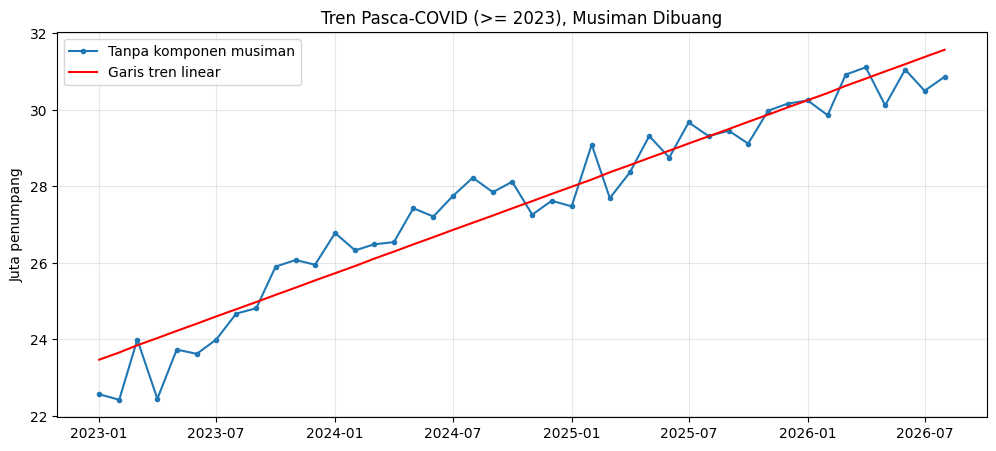

Catatan: data bulanan berautokorelasi, sehingga p-value cenderung terlalu optimistis.
Gunakan hasil ini sebagai indikasi awal, bukan bukti akhir.

Rata-rata bulanan (juta penumpang):
  2016: 23.38  (12 bulan)
  2017: 26.32  (12 bulan)
  2018: 28.07  (12 bulan)
  2019: 28.00  (12 bulan)
  2023: 24.24  (12 bulan)
  2024: 27.35  (12 bulan)
  2025: 29.07  (12 bulan)
  2026: 30.08  (8 bulan)


In [14]:
# Hipotesis di dokumen proyek: penumpang tercatat cenderung mendatar
# (diduga karena keterbatasan kapasitas).
# Uji: regresi linear sederhana nilai ~ waktu pada data >= 2023.
# Jika kemiringan (slope) mendekati nol dan tidak signifikan -> mendatar.

def uji_tren(seri, nama):
    t = np.arange(len(seri))
    hasil = stats.linregress(t, seri.values)

    slope = hasil.slope                       # juta per bulan
    se = hasil.stderr
    t_kritis = stats.t.ppf(0.975, df=len(seri) - 2)
    ci_bawah = slope - t_kritis * se
    ci_atas = slope + t_kritis * se
    persen_per_tahun = slope * 12 / seri.mean() * 100

    print(f"--- {nama} (n={len(seri)}) ---")
    print(f"Slope            : {slope:.4f} juta/bulan")
    print(f"CI 95% slope     : [{ci_bawah:.4f}, {ci_atas:.4f}]")
    print(f"Setara           : {persen_per_tahun:.2f}% per tahun")
    print(f"p-value          : {hasil.pvalue:.4f}")
    print(f"R-kuadrat        : {hasil.rvalue**2:.3f}")
    print()
    return hasil


data_pasca = df[df.index >= PASCA_COVID]

# (a) data asli
uji_tren(data_pasca["penumpang_juta"], "Data asli pasca-2023")

# (b) data tanpa komponen musiman (hasil STL), supaya fluktuasi musiman tidak mengganggu
seri_tanpa_musim = df["penumpang_juta"] - stl.seasonal
hasil_b = uji_tren(seri_tanpa_musim[seri_tanpa_musim.index >= PASCA_COVID],
                   "Setelah musiman dibuang pasca-2023")

# grafik
fig, ax = plt.subplots()
y_b = seri_tanpa_musim[seri_tanpa_musim.index >= PASCA_COVID]
t = np.arange(len(y_b))
ax.plot(y_b.index, y_b.values, marker="o", markersize=3, label="Tanpa komponen musiman")
ax.plot(y_b.index, hasil_b.intercept + hasil_b.slope * t, color="red", label="Garis tren linear")
ax.set_title("Tren Pasca-COVID (>= 2023), Musiman Dibuang")
ax.set_ylabel("Juta penumpang")
ax.legend()
simpan_gambar("eda_09_tren_pasca_covid.png")
plt.show()

print("Catatan: data bulanan berautokorelasi, sehingga p-value cenderung terlalu optimistis.")
print("Gunakan hasil ini sebagai indikasi awal, bukan bukti akhir.")

# perbandingan level dengan sebelum COVID
print("\nRata-rata bulanan (juta penumpang):")
for th in [2016, 2017, 2018, 2019, 2023, 2024, 2025, 2026]:
    if th in tahunan.index:
        print(f"  {th}: {tahunan.loc[th, 'rata_bulanan_juta']:.2f}  ({int(tahunan.loc[th, 'jumlah_bulan'])} bulan)")

In [15]:
print("=== RINGKASAN ANGKA KUNCI ===")
print(f"Jumlah observasi          : {len(df)}")
print(f"Periode                   : {df.index.min().strftime('%Y-%m')} sampai {df.index.max().strftime('%Y-%m')}")
print(f"Nilai terendah            : {df['penumpang_juta'].min():.2f} juta ({df['penumpang_juta'].idxmin().strftime('%Y-%m')})")
print(f"Nilai tertinggi           : {df['penumpang_juta'].max():.2f} juta ({df['penumpang_juta'].idxmax().strftime('%Y-%m')})")
print(f"Kekuatan tren (STL)       : {kekuatan_tren:.3f}")
print(f"Kekuatan musiman (STL)    : {kekuatan_musiman:.3f}")
print(f"Efek Lebaran (rata-rata)  : {tabel_lebaran['selisih_%'].mean():.1f}% vs bulan tetangga")
print(f"Slope pasca-2023 (tanpa musim): {hasil_b.slope:.4f} juta/bulan (p={hasil_b.pvalue:.4f})")

=== RINGKASAN ANGKA KUNCI ===
Jumlah observasi          : 128
Periode                   : 2016-01 sampai 2026-08
Nilai terendah            : 5.08 juta (2020-05)
Nilai tertinggi           : 32.47 juta (2026-07)
Kekuatan tren (STL)       : 0.844
Kekuatan musiman (STL)    : 0.017
Efek Lebaran (rata-rata)  : -7.2% vs bulan tetangga
Slope pasca-2023 (tanpa musim): 0.1884 juta/bulan (p=0.0000)
